# 01 Understanding the Data: CIFAR-10 

## Objective

In this notebook, we will explore **CIFAR-10**, a small, well-known image-classification dataset. We'll use it to learn the workflow, then adapt the same ideas to **EuroSAT RGB** for satellite land-cover classification.

By the end, you should be able to:
- Explain samples, features, labels, and classes.
- Load and inspect an image dataset.
- Visualize images and labels.
- Inspect class distribution.
- Explain why image normalization is useful.

## Our task

**Given an image, predict which of 10 object categories it belongs to.**

CIFAR-10 is our teaching dataset—not our final satellite application. Its classes are everyday objects, while EuroSAT contains satellite images of land-cover types.

## 1. Key terminology

- **Sample:** One image in the dataset.
- **Feature/input:** The information provided to the model. Here, it is the image's RGB pixel values.
- **Label:** The correct answer associated with an image.
- **Class:** One category the model can predict.
- **Classification:** Predicting a discrete category rather than a continuous number.

For example, an image may have the label `ship`. The model learns visual patterns from labelled examples; it does not begin with a human understanding of what a ship is.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.datasets import cifar10

print("TensorFlow:", tf.__version__)
print("NumPy:", np.__version__)
print("GPU devices:", tf.config.list_physical_devices("GPU"))

2026-11-01 17:49:25.066702: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-11-01 17:49:25.126249: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1793555365.147916   10851 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1793555365.154693   10851 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1793555365.208608   10851 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking 

TensorFlow: 2.19.1
NumPy: 2.1.3
GPU devices: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 2. Load CIFAR-10

Keras provides a built-in loader for CIFAR-10. On the first run, it downloads the dataset and caches it locally; later runs can reuse the cached copy.

The dataset comes with an official training set and test set:
- **Training set:** used to learn model parameters.
- **Test set:** held back to estimate performance on unseen examples.

We will not use the test set to make training decisions. In the next notebook, we will split the training data into training and validation subsets.

In [2]:
from tensorflow.keras.datasets import cifar10
from sklearn.model_selection import train_test_split

# 1. Load CIFAR-10
(x_train, y_train), (x_test, y_test) = cifar10.load_data()

# 2. Make labels 1D
y_train = y_train.flatten()
y_test = y_test.flatten()

# 3. Split training data into train and validation sets
x_train, x_val, y_train, y_val = train_test_split(
    x_train,
    y_train,
    test_size=0.1,
    random_state=42
)

# 4. Class names
class_names = [
    "airplane", "automobile", "bird", "cat", "deer",
    "dog", "frog", "horse", "ship", "truck"
]

# 5. Print dataset sizes
print("Training:", x_train.shape)
print("Validation:", x_val.shape)
print("Testing:", x_test.shape)

Training: (45000, 32, 32, 3)
Validation: (5000, 32, 32, 3)
Testing: (10000, 32, 32, 3)


## 3. Interpret the shape

A CIFAR-10 image has shape **`(32, 32, 3)`**:
- `32`: image height in pixels.
- `32`: image width in pixels.
- `3`: red, green, and blue colour channels.

The label is an integer from `0` to `9`. We use `class_names` to map that integer to a readable class name.

Ask yourself: what information might be lost when an image is only 32 × 32 pixels?

Image shape: (32, 32, 3)
Label integer: 3
Label name: cat


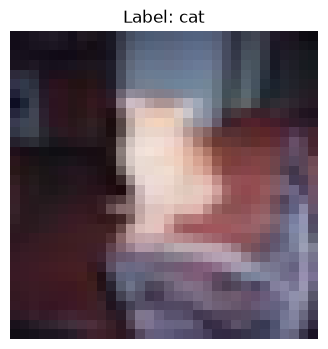

In [4]:
sample_index = 0
image = x_train[sample_index]
label = int(y_train[sample_index])

print("Image shape:", image.shape)
print("Label integer:", label)
print("Label name:", class_names[label])

plt.figure(figsize=(4, 4))
plt.imshow(image)
plt.title(f"Label: {class_names[label]}")
plt.axis("off")
plt.show()

## 4. Visualize a grid of samples

A single image does not show the variation within a dataset. Display a grid of randomly selected training images and inspect whether the objects are always centred, clearly visible, or easy to distinguish.

**Mini-task:** Find two images that might be difficult for a model to distinguish. Explain what makes them challenging.

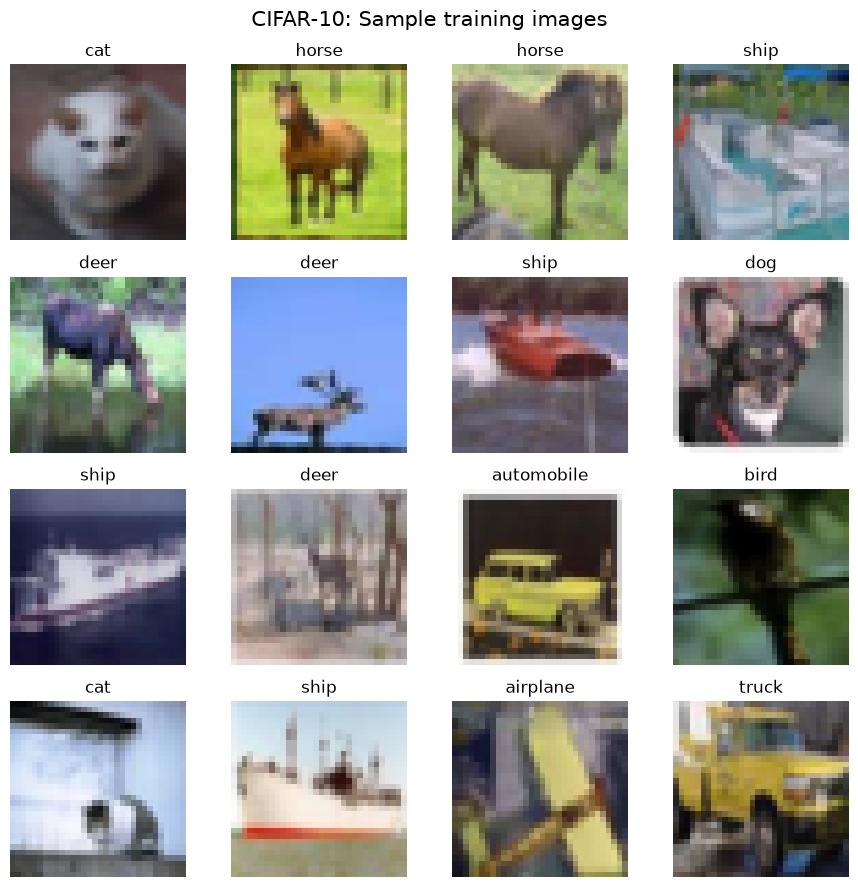

In [5]:
rng = np.random.default_rng(42)
indices = rng.choice(len(x_train), size=16, replace=False)

fig, axes = plt.subplots(4, 4, figsize=(9, 9))

for ax, idx in zip(axes.flat, indices):
    ax.imshow(x_train[idx])
    ax.set_title(class_names[int(y_train[idx])])
    ax.axis("off")

fig.suptitle("CIFAR-10: Sample training images", fontsize=15)
plt.tight_layout()
plt.show()

## 5. Inspect class distribution

Class distribution tells us how many examples belong to each category. If some classes have far fewer examples than others, overall accuracy can hide poor performance on underrepresented classes. This is one form of **class imbalance**.

Let's count the labels rather than assume the classes are balanced.

airplane    :  4524 images
automobile  :  4513 images
bird        :  4473 images
cat         :  4477 images
deer        :  4514 images
dog         :  4496 images
frog        :  4515 images
horse       :  4491 images
ship        :  4497 images
truck       :  4500 images


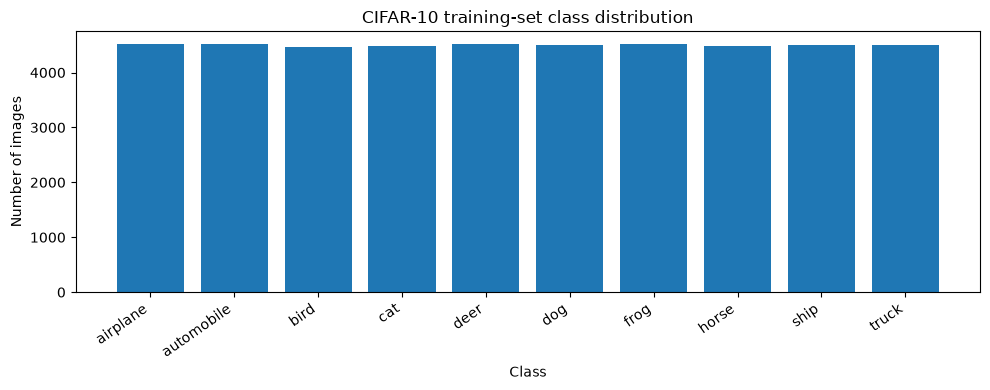

In [6]:
class_counts = np.bincount(y_train, minlength=len(class_names))

for name, count in zip(class_names, class_counts):
    print(f"{name:12s}: {count:5d} images")

plt.figure(figsize=(10, 4))
plt.bar(class_names, class_counts)
plt.title("CIFAR-10 training-set class distribution")
plt.xlabel("Class")
plt.ylabel("Number of images")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

## 6. Pixel values and normalization

The original pixel values are integers from **0 to 255**. Neural networks often train more effectively when inputs use a smaller numerical range.

A common transformation is:

\\[
x_{\\text{normalized}} = \\frac{x}{255}
\\]

This maps pixel values into the range 0–1. We will create normalized arrays for illustration, while keeping the original arrays unchanged.

Original dtype: uint8
Original range: 0 to 255
Normalized dtype: float32
Normalized range: 0.0 to 1.0


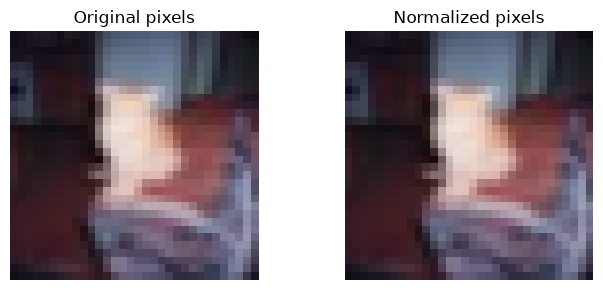

In [7]:
x_train_normalized = x_train.astype("float32") / 255.0
x_test_normalized = x_test.astype("float32") / 255.0

print("Original dtype:", x_train.dtype)
print("Original range:", int(x_train.min()), "to", int(x_train.max()))
print("Normalized dtype:", x_train_normalized.dtype)
print("Normalized range:",
      float(x_train_normalized.min()),
      "to",
      float(x_train_normalized.max()))

fig, axes = plt.subplots(1, 2, figsize=(7, 3))
axes[0].imshow(x_train[0])
axes[0].set_title("Original pixels")
axes[1].imshow(x_train_normalized[0])
axes[1].set_title("Normalized pixels")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

## 7. Check your understanding

Answer these in your own words:

1. What is the difference between a feature and a label?
2. What does `(32, 32, 3)` mean?
3. Why do we keep the test set separate from training?
4. Why do we normalize pixel values?
5. Give one reason a CIFAR-10 image might be difficult to classify.
6. What is the difference between classification and regression?

### Mini-challenge

Pick one CIFAR-10 class. Describe two visual cues that might help a model recognize it, and one situation in which those cues might fail.

## 8. Transfer the workflow to EuroSAT 🛰️

CIFAR-10 is for learning the workflow. Your next challenge is to apply the same ideas to **EuroSAT RGB**, which contains satellite images labelled by land-cover class.

For your EuroSAT adaptation, you should independently:

- Obtain the **RGB** version (not the much larger 13-band multispectral version).
- Identify the directory containing the 10 class folders.
- Load images and labels.
- Print image shape, data type, pixel range, class names, and sample counts.
- Visualize a grid of images.
- Plot class distribution.
- Explain at least two ways EuroSAT differs from CIFAR-10.

**Important:** Do not reuse CIFAR-10 class names or assume the same image dimensions. Inspect the target dataset and verify its properties.

### What comes next?

In `02_preprocessing_and_splits.ipynb`, we will create a reproducible training/validation split and build an input pipeline suitable for model training.